In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
import funcionalidades as fn

Media PVREAD 25 ESPAÑA: 451 puntos 
Media PVREAD 25 OCDE: 461 puntos 
Puntuación media en lectura VALENCIA (promedio de los 10 PVs): 423.52
Media Ponderada pvread1:     423.78
Mediana Ponderada pvread1:   427.94
Desv. Est. Ponderada pvread1: 95.08

In [45]:
archivo_valencia25 = 'data/pisa_valencia25.csv'
df_valencia25=pd.read_csv(archivo_valencia25)

archivo_valencia22 = 'data/pisa_valencia22.csv'
df_valencia22=pd.read_csv(archivo_valencia22)

archivo_valencia18 = 'data/pisa_valencia18.csv'
df_valencia18=pd.read_csv(archivo_valencia18)


--- RESULTADO OFICIAL PISA 2025 (VALENCIA) ---
Puntuación media en lectura para 2025 (promedio de los 10 PVs): 423.52
ESTADÍSTICAS DESCRIPTIVAS PONDERADAS PVREAD1: Rendimiento Lector 2025
Media Ponderada:     423.78
Mediana Ponderada:   427.94
Desv. Est. Ponderada:95.08


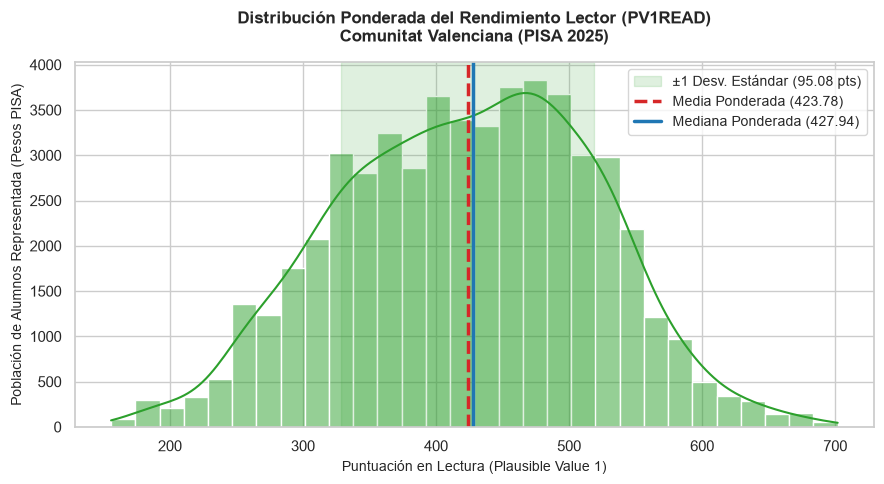

In [37]:
# Definimos la lista con las 10 columnas de lectura de PISA
pv_cols = [f'PV{i}READ' for i in range(1, 11)]
cols_w_rep=[f"W_FSTURWT{i}" for i in range(1, 81)]
medias_lectura25 = []

# Bucle para calcular la media ponderada en cada uno de los 10 valores plausibles. primero pv1, luego pv2..
for pv in pv_cols:
    # Multiplicamos la nota por el peso del alumno para que sea representativo: pv1*w1
    # Sumamos toda la col 
    # (Media ponderada: suma de (nota * peso) / suma de pesos)
    lectura_ponderada25 = (df_valencia25[pv] * df_valencia25['W_FSTUWT']).sum()
    suma_pesos25 = df_valencia25['W_FSTUWT'].sum()
    
    media_pv25 = lectura_ponderada25 / suma_pesos25
    medias_lectura25.append(media_pv25)

# Promediamos los 10 resultados de los mundos de PISA
media_lectura_definitiva25 = np.mean(medias_lectura25)

print(f"--- RESULTADO OFICIAL PISA 2025 (VALENCIA) ---")
print(f"Puntuación media en lectura para 2025 (promedio de los 10 PVs): {media_lectura_definitiva25:.2f}")

# CÁLCULO DE ESTADÍSTICAS PONDERADAS 2025 para PVREAD1 (PISA)
# =====================================================================
# A. Media Ponderada (usando numpy.average con pesos)
media_pond25 = np.average(df_valencia25['PV1READ'], weights=df_valencia25['W_FSTUWT'])

# B. Desviación Estándar Ponderada
# Fórmula: Raíz cuadrada de la media ponderada de las desviaciones al cuadrado
variance_pond25 = np.average((df_valencia25['PV1READ'] - media_pond25)**2, weights=df_valencia25['W_FSTUWT'])
desv_pond25 = np.sqrt(variance_pond25)

# C. Mediana Ponderada (el valor donde se acumula el 50% de la población ponderada)
def calcular_mediana_ponderada(vals, wts):
    df_temporal = pd.DataFrame({'val': vals, 'wt': wts}).sort_values('val')
    wt_acumulado = df_temporal['wt'].cumsum()
    valormedio_wt = df_temporal['wt'].sum() / 2.0
    return df_temporal.loc[wt_acumulado >= valormedio_wt, 'val'].iloc[0]
mediana_pond25 = calcular_mediana_ponderada(df_valencia25['PV1READ'], df_valencia25['W_FSTUWT'])

# Imprimimos los resultados oficiales corregidos
print("==================================================")
print("ESTADÍSTICAS DESCRIPTIVAS PONDERADAS PVREAD1: Rendimiento Lector 2025")
print("==================================================")
print(f"Media Ponderada:     {media_pond25:.2f}")
print(f"Mediana Ponderada:   {mediana_pond25:.2f}")
print(f"Desv. Est. Ponderada:{desv_pond25:.2f}")
# print(f"Mínimo de la muestra:{min_val:.2f}")
# print(f"Máximo de la muestra:{max_val:.2f}")

# GRÁFICO PARA PV1READ  
df_lectura_ponderada25=df_valencia25[['PV1READ', 'W_FSTUWT']].dropna()
# Configuramos el estilo estético limpio
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Dibujamos el histograma con pesos (weights)
sns.histplot(
    data=df_lectura_ponderada25,
    x='PV1READ',
    weights='W_FSTUWT',       # <--- AQUÍ APLICAMOS EL PESO MUESTRAL DE PISA
    kde=True,                 # Añade la curva de densidad suavizada
    color='#2ca02c',          # Color verde representativo
    bins=30                   # Número de barras
)

# 4. Representar la dispersión: Rango de +-1 Desviación Estándar (68% central de alumnos)
plt.axvspan(
    media_pond25 - desv_pond25, 
    media_pond25 + desv_pond25, 
    color='#2ca02c', 
    alpha=0.15,          # Sombreado suave verde
    label=f'±1 Desv. Estándar ({desv_pond25:.2f} pts)'
)

# 4. Añadimos las líneas verticales de la Media y la Mediana ponderadas
plt.axvline(
    x=media_pond25, 
    color='#d62728',         # Rojo
    linestyle='--', 
    linewidth=2.5, 
    label=f'Media Ponderada ({media_pond25:.2f})'
)

plt.axvline(
    x=mediana_pond25, 
    color='#1f77b4',         # Azul
    linestyle='-', 
    linewidth=2.5, 
    label=f'Mediana Ponderada ({mediana_pond25:.2f})'
)

# 4. Títulos y etiquetas descriptivas
plt.title('Distribución Ponderada del Rendimiento Lector (PV1READ)\nComunitat Valenciana (PISA 2025)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Puntuación en Lectura (Plausible Value 1)', fontsize=10)
plt.ylabel('Población de Alumnos Representada (Pesos PISA)', fontsize=10)

# Mostramos la leyenda ordenadamente arriba a la derecha
plt.legend(fontsize=10, loc='upper right', frameon=True)

# 5. Ajustes y renderizado
plt.tight_layout()
plt.show()

In [42]:
print(df_valencia22.shape, df_valencia18.shape)
print("df22 conserva réplicas:", len([c for c in df22.columns if "RWT" in c]))

(1625, 17) (1753, 16)


NameError: name 'df22' is not defined

In [44]:
# ---------------------------ERRORES---------------------------
# 3) Función de la media ponderada: suma(nota x peso) / suma(pesos)

def media_pond(notas, pesos):
    return (notas * pesos).sum() / pesos.sum()

cols_w_rep=[f"W_FSTURWT{i}" for i in range(1, 81)]

medias_pv = []        # aquí guardaremos la media de cada PV (10 valores)
varianzas_pv = []     # y aquí la varianza muestral de cada PV (10 valores)

for pv in pv_cols:
    # 4) Media con el peso final (la estimación principal)
    media_total = media_pond(df_valencia25[pv], df_valencia25["W_FSTUWT"])

    # 5) Media con cada uno de los 80 pesos replicados
    medias_w_rep = []
    for c in cols_w_rep:
        medias_w_rep.append(media_pond(df_valencia25[pv], df_valencia25[c]))

    # 6) Varianza muestral: suma de (media_réplica - media_total)^2, dividida entre 20.
    # El 20 sale de las 80 réplicas del diseño de PISA y de su factor de ajuste (80 × 0,5²). Es una constante del método.
    suma_cuadrados = 0 
    for m in medias_w_rep:                                  # una vuelta por cada peso replicado (80 vueltas)      
        diferencia = m - media_total                        # 3) cuánto se aleja de la media con el peso final
        suma_cuadrados = suma_cuadrados + diferencia ** 2   # 4) la elevamos al cuadrado y la sumamos

    varianza = suma_cuadrados / 20                          # 5) dividimos entre 20 (constante del método BRR de PISA)
    error = np.sqrt(varianza)    
    medias_pv.append(media_total)                                # guardamos la media de esta PV
    varianzas_pv.append(suma_cuadrados / 20)                 # y su varianza muestral                           # 6) el error típico es la raíz de la varianza

    

# Combinar las 10 PV
media_final = np.mean(medias_pv)           # estimación final: promedio de las 10 medias
U = np.mean(varianzas_pv)                  # varianza muestral media
B = np.var(medias_pv, ddof=1)              # varianza entre las 10 PV (imputación)
error_final = np.sqrt(U + (1 + 1/10) * B)  # error típico total

print("Media (10 PV):", round(media_final, 2))
print("Error típico total:", round(error_final, 2))
print("Parte muestral (U):", round(U, 2), "| parte imputación (B):", round(B, 2))

Media (10 PV): 423.52
Error típico total: 5.79
Parte muestral (U): 32.02 | parte imputación (B): 1.34


In [35]:
for nombre, df in [("2025", df_valencia25), ("2022", df_valencia22), ("2018", df_valencia18)]:
    faltan_rep = [c for c in cols_w_rep if c not in df.columns]
    faltan_pv = [c for c in pv_cols if c not in df.columns]
    print(nombre, "| filas:", df.shape[0], "| centros:", df["CNTSCHID"].nunique(),
          "| réplicas que faltan:", len(faltan_rep), "| PV que faltan:", len(faltan_pv))

2025 | filas: 1712 | centros: 54 | réplicas que faltan: 0 | PV que faltan: 0
2022 | filas: 1625 | centros: 53 | réplicas que faltan: 80 | PV que faltan: 0
2018 | filas: 1753 | centros: 53 | réplicas que faltan: 80 | PV que faltan: 0


In [47]:
def media_pond(notas, pesos):
    return (notas * pesos).sum() / pesos.sum()

def media_con_error(df, pv_cols, rep_cols, peso="W_FSTUWT"):
    
    medias_pv = []
    varianzas_pv = []
    for pv in pv_cols:
        media_total = media_pond(df[pv], df[peso])
        suma_cuadrados = 0
        for c in rep_cols:
            m = media_pond(df[pv], df[c])
            suma_cuadrados = suma_cuadrados + (m - media_total) ** 2
        medias_pv.append(media_total)
        varianzas_pv.append(suma_cuadrados / 20)

    media_final = np.mean(medias_pv)
    # varianza muestral media
    U = np.mean(varianzas_pv)
    # varianza entre las 10 PV (imputación)
    B = np.var(medias_pv, ddof=1)

    error = np.sqrt(U + (1 + 1 / len(pv_cols)) * B)
    return media_final, error, len(df)

media25, error25, n25 = media_con_error(df_valencia25, pv_cols, cols_w_rep)
print(round(media25, 2), round(error25, 2), n25)

media22, error22, n22 = media_con_error(df_valencia22, pv_cols, cols_w_rep)
print(round(media22, 2), round(error22, 2), n22)

media18, error18, n18 = media_con_error(df_valencia18, pv_cols, cols_w_rep)
print(round(media18, 2), round(error18, 2), n18)

423.52 5.79 1712
481.76 3.98 1625
472.69 4.52 1753


In [4]:
# Inspeccionar los valores únicos de las variables geográficas
# print("--- Valores en SUBNATIO ---")
# print(df_valencia['SUBNATIO'].value_counts(dropna=False))

# print("\n--- Valores en REGION ---")
# print(df_valencia['REGION'].value_counts(dropna=False))
# print(df_valencia["CNTSTUID"].nunique())
# print(df_valencia.groupby("CNTSCHID")["CNTSTUID"].nunique().describe())
# df_valencia["CNTSCHID"].unique().tolist()

--- RESULTADO OFICIAL PISA 2022 (VALENCIA) ---
Puntuación media en lectura para 2022 (promedio de los 10 PVs): 481.76
ESTADÍSTICAS DESCRIPTIVAS PONDERADAS: Rendimiento Lector (PV1READ) 2022
Media Ponderada:     483.54
Mediana Ponderada:   485.20
Desv. Est. Ponderada:97.74


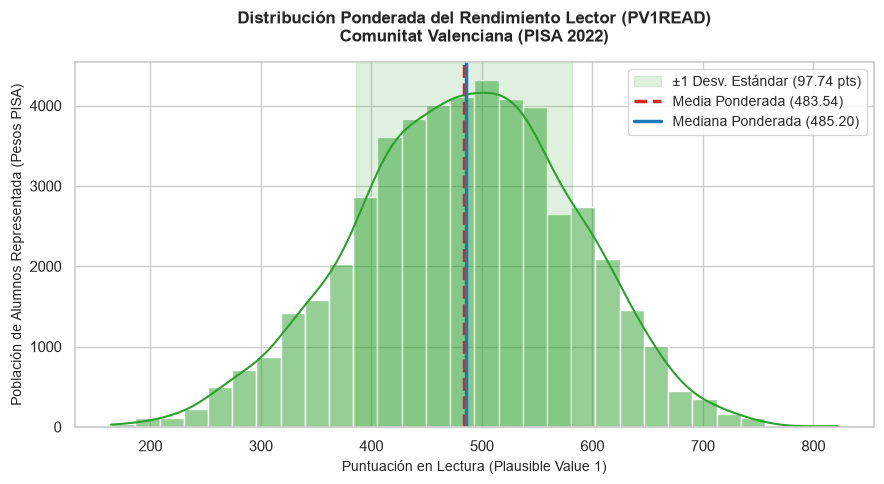

In [17]:
# Definimos la lista con las 10 columnas de lectura de PISA
pv_cols22 = [f'PV{i}READ' for i in range(1, 11)]

medias_lectura22 = []

# Bucle para calcular la media ponderada en cada uno de los 10 valores plausibles. primero pv1, luego pv2..
for pv in pv_cols22:
    # Multiplicamos la nota por el peso del alumno para que sea representativo: pv1*w1
    # Sumamos toda la col 
    # (Media ponderada: suma de (nota * peso) / suma de pesos)
    lectura_ponderada22 = (df_valencia22[pv] * df_valencia22['W_FSTUWT']).sum()
    suma_pesos22 = df_valencia22['W_FSTUWT'].sum()
    
    media_pv22 = lectura_ponderada22 / suma_pesos22
    medias_lectura22.append(media_pv22)

# Promediamos los 10 resultados de los mundos de PISA
media_lectura_definitiva22 = np.mean(medias_lectura22)

print(f"--- RESULTADO OFICIAL PISA 2022 (VALENCIA) ---")
print(f"Puntuación media en lectura para 2022 (promedio de los 10 PVs): {media_lectura_definitiva22:.2f}")

# CÁLCULO DE ESTADÍSTICAS PONDERADAS 2022 (PISA) PVREAD1
# =====================================================================
# A. Media Ponderada (usando numpy.average con pesos)
media_pond22 = np.average(df_valencia22['PV1READ'], weights=df_valencia22['W_FSTUWT'])

# B. Desviación Estándar Ponderada
# Fórmula: Raíz cuadrada de la media ponderada de las desviaciones al cuadrado
variance_pond22 = np.average((df_valencia22['PV1READ'] - media_pond22)**2, weights=df_valencia22['W_FSTUWT'])
desv_pond22 = np.sqrt(variance_pond22)

# C. Mediana Ponderada (el valor donde se acumula el 50% de la población ponderada)
def calcular_mediana_ponderada(vals, wts):
    df_temporal = pd.DataFrame({'val': vals, 'wt': wts}).sort_values('val')
    wt_acumulado = df_temporal['wt'].cumsum()
    valormedio_wt = df_temporal['wt'].sum() / 2.0
    return df_temporal.loc[wt_acumulado >= valormedio_wt, 'val'].iloc[0]
mediana_pond22 = calcular_mediana_ponderada(df_valencia22['PV1READ'], df_valencia22['W_FSTUWT'])

# Imprimimos los resultados oficiales corregidos
print("==================================================")
print("ESTADÍSTICAS DESCRIPTIVAS PONDERADAS: Rendimiento Lector (PV1READ) 2022")
print("==================================================")
print(f"Media Ponderada:     {media_pond22:.2f}")
print(f"Mediana Ponderada:   {mediana_pond22:.2f}")
print(f"Desv. Est. Ponderada:{desv_pond22:.2f}")
# print(f"Mínimo de la muestra:{min_val:.2f}")
# print(f"Máximo de la muestra:{max_val:.2f}")

# GRÁFICO PARA PV1READ  
df_lectura_ponderada22=df_valencia22[['PV1READ', 'W_FSTUWT']].dropna()
# Configuramos el estilo estético limpio
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Dibujamos el histograma con pesos (weights)
sns.histplot(
    data=df_lectura_ponderada22,
    x='PV1READ',
    weights='W_FSTUWT',       # <--- AQUÍ APLICAMOS EL PESO MUESTRAL DE PISA
    kde=True,                 # Añade la curva de densidad suavizada
    color='#2ca02c',          # Color verde representativo
    bins=30                   # Número de barras
)

# 4. Representar la dispersión: Rango de +-1 Desviación Estándar (68% central de alumnos)
plt.axvspan(
    media_pond22 - desv_pond22, 
    media_pond22 + desv_pond22, 
    color='#2ca02c', 
    alpha=0.15,          # Sombreado suave verde
    label=f'±1 Desv. Estándar ({desv_pond22:.2f} pts)'
)

# 4. Añadimos las líneas verticales de la Media y la Mediana ponderadas
plt.axvline(
    x=media_pond22, 
    color='#d62728',         # Rojo
    linestyle='--', 
    linewidth=2.5, 
    label=f'Media Ponderada ({media_pond22:.2f})'
)

plt.axvline(
    x=mediana_pond22, 
    color='#1f77b4',         # Azul
    linestyle='-', 
    linewidth=2.5, 
    label=f'Mediana Ponderada ({mediana_pond22:.2f})'
)

# 4. Títulos y etiquetas descriptivas
plt.title('Distribución Ponderada del Rendimiento Lector (PV1READ)\nComunitat Valenciana (PISA 2022)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Puntuación en Lectura (Plausible Value 1)', fontsize=10)
plt.ylabel('Población de Alumnos Representada (Pesos PISA)', fontsize=10)

# Mostramos la leyenda ordenadamente arriba a la derecha
plt.legend(fontsize=10, loc='upper right', frameon=True)

# 5. Ajustes y renderizado
plt.tight_layout()
plt.show()

--- RESULTADO OFICIAL PISA 2018 (VALENCIA) ---
Puntuación media en lectura para 2018 (promedio de los 10 PVs): 472.69
ESTADÍSTICAS DESCRIPTIVAS PONDERADAS: Rendimiento Lector (PV1READ) 2018
Media Ponderada:     473.03
Mediana Ponderada:   477.66
Desv. Est. Ponderada:90.45


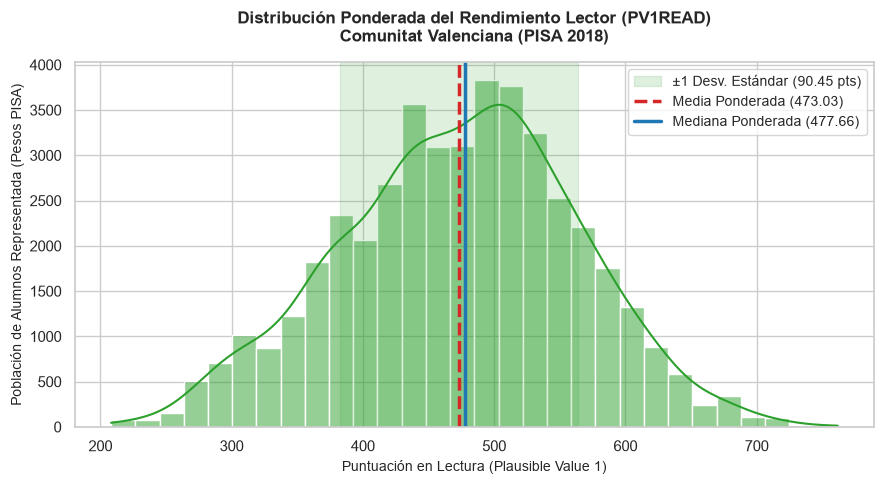

In [19]:
# Definimos la lista con las 10 columnas de lectura de PISA
pv_cols18 = [f'PV{i}READ' for i in range(1, 11)]

medias_lectura18 = []

# Bucle para calcular la media ponderada en cada uno de los 10 valores plausibles. primero pv1, luego pv2..
for pv in pv_cols18:
    # Multiplicamos la nota por el peso del alumno para que sea representativo: pv1*w1
    # Sumamos toda la col 
    # (Media ponderada: suma de (nota * peso) / suma de pesos)
    lectura_ponderada18 = (df_valencia18[pv] * df_valencia18['W_FSTUWT']).sum()
    suma_pesos18 = df_valencia18['W_FSTUWT'].sum()
    
    media_pv18 = lectura_ponderada18 / suma_pesos18
    medias_lectura18.append(media_pv18)

# Promediamos los 10 resultados de los mundos de PISA
media_lectura_definitiva18 = np.mean(medias_lectura18)

print(f"--- RESULTADO OFICIAL PISA 2018 (VALENCIA) ---")
print(f"Puntuación media en lectura para 2018 (promedio de los 10 PVs): {media_lectura_definitiva18:.2f}")

# CÁLCULO DE ESTADÍSTICAS PONDERADAS 2018 (PISA) PVREAD1
# =====================================================================
# A. Media Ponderada (usando numpy.average con pesos)
media_pond18 = np.average(df_valencia18['PV1READ'], weights=df_valencia18['W_FSTUWT'])

# B. Desviación Estándar Ponderada
# Fórmula: Raíz cuadrada de la media ponderada de las desviaciones al cuadrado
variance_pond18 = np.average((df_valencia18['PV1READ'] - media_pond18)**2, weights=df_valencia18['W_FSTUWT'])
desv_pond18 = np.sqrt(variance_pond18)

# C. Mediana Ponderada (el valor donde se acumula el 50% de la población ponderada)
def calcular_mediana_ponderada(vals, wts):
    df_temporal = pd.DataFrame({'val': vals, 'wt': wts}).sort_values('val')
    wt_acumulado = df_temporal['wt'].cumsum()
    valormedio_wt = df_temporal['wt'].sum() / 2.0
    return df_temporal.loc[wt_acumulado >= valormedio_wt, 'val'].iloc[0]
mediana_pond18 = calcular_mediana_ponderada(df_valencia18['PV1READ'], df_valencia18['W_FSTUWT'])

# Imprimimos los resultados oficiales corregidos
print("==================================================")
print("ESTADÍSTICAS DESCRIPTIVAS PONDERADAS: Rendimiento Lector (PV1READ) 2018")
print("==================================================")
print(f"Media Ponderada:     {media_pond18:.2f}")
print(f"Mediana Ponderada:   {mediana_pond18:.2f}")
print(f"Desv. Est. Ponderada:{desv_pond18:.2f}")
# print(f"Mínimo de la muestra:{min_val:.2f}")
# print(f"Máximo de la muestra:{max_val:.2f}")

# GRÁFICO PARA PV1READ  
df_lectura_ponderada18=df_valencia18[['PV1READ', 'W_FSTUWT']].dropna()
# Configuramos el estilo estético limpio
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Dibujamos el histograma con pesos (weights)
sns.histplot(
    data=df_lectura_ponderada18,
    x='PV1READ',
    weights='W_FSTUWT',       # <--- AQUÍ APLICAMOS EL PESO MUESTRAL DE PISA
    kde=True,                 # Añade la curva de densidad suavizada
    color='#2ca02c',          # Color verde representativo
    bins=30                   # Número de barras
)

# 4. Representar la dispersión: Rango de +-1 Desviación Estándar (68% central de alumnos)
plt.axvspan(
    media_pond18 - desv_pond18, 
    media_pond18 + desv_pond18, 
    color='#2ca02c', 
    alpha=0.15,          # Sombreado suave verde
    label=f'±1 Desv. Estándar ({desv_pond18:.2f} pts)'
)

# 4. Añadimos las líneas verticales de la Media y la Mediana ponderadas
plt.axvline(
    x=media_pond18, 
    color='#d62728',         # Rojo
    linestyle='--', 
    linewidth=2.5, 
    label=f'Media Ponderada ({media_pond18:.2f})'
)

plt.axvline(
    x=mediana_pond18, 
    color='#1f77b4',         # Azul
    linestyle='-', 
    linewidth=2.5, 
    label=f'Mediana Ponderada ({mediana_pond18:.2f})'
)

# 4. Títulos y etiquetas descriptivas
plt.title('Distribución Ponderada del Rendimiento Lector (PV1READ)\nComunitat Valenciana (PISA 2018)', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Puntuación en Lectura (Plausible Value 1)', fontsize=10)
plt.ylabel('Población de Alumnos Representada (Pesos PISA)', fontsize=10)

# Mostramos la leyenda ordenadamente arriba a la derecha
plt.legend(fontsize=10, loc='upper right', frameon=True)

# 5. Ajustes y renderizado
plt.tight_layout()
plt.show()